# Первое зимнее обучение

Пять подтвержденных погожих дней LFPG 09L, 2025 год. Обучение: 10 января, 13 января и 2 февраля; валидация 15 февраля; неизменный тест 21 февраля. Сравниваем четыре простые модели поправки к прогнозу с постоянной вертикальной скоростью. Это промежуточный расчет на готовых днях; сезонный набор из 39 дней еще собирается

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

base = Path.cwd()
sys.path.insert(0, str(base / 'scripts'))
from train_models import FAMILIES, fit, forecast, summarize
dates = ['2025-01-10', '2025-01-13', '2025-02-02', '2025-02-15', '2025-02-21']
data = pd.concat([pd.read_parquet(base / 'data' / day / 'examples.parquet') for day in dates], ignore_index=True)
features = json.loads((base.parents[1] / 'configs/lfpg_09l_training.json').read_text(encoding='utf-8'))['features']
train = data.loc[data.day.isin(dates[:3])]
validation = data.loc[data.day.eq(dates[3])]
test = data.loc[data.day.eq(dates[4])]
assert set(train.event_id).isdisjoint(test.event_id)
assert set(validation.event_id).isdisjoint(test.event_id)
assert data.origin_metar_available_time.le(data.origin_time).all()
display(data.groupby('day').agg(Заходов=('event_id', 'nunique'), Пар=('event_id', 'size')))


,Заходов,Пар
day,,
2025-01-10,34,565
2025-01-13,26,472
2025-02-02,95,1834
2025-02-15,83,1628
2025-02-21,93,1793


In [2]:
selected = {}
results, search = [], []
for name, options in FAMILIES.items():
    candidates = []
    for option in options:
        model, converged = fit(name, option, train, features)
        score = summarize(validation, forecast(model, validation, features), name)['macro_mae_ft']
        search.append({'model': name, 'parameters': json.dumps(option), 'validation_mae_ft': score, 'converged': converged})
        if converged:
            candidates.append((score, option, model))
    assert candidates
    _, parameters, model = min(candidates, key=lambda row: row[0])
    selected[name] = parameters
    results.append(summarize(test, forecast(model, test, features), name))
results.append(summarize(test, test.baseline_ft, 'Constant vertical rate'))
metrics = pd.DataFrame(results).sort_values('macro_mae_ft')
metrics.to_csv(base / 'reports/winter_pilot_metrics.csv', index=False)
pd.DataFrame(search).to_csv(base / 'reports/winter_pilot_search.csv', index=False)
display(metrics[['model', 'macro_mae_ft', 'point_p95_abs_ft']].rename(columns={
    'model': 'Модель', 'macro_mae_ft': 'MAE, ft', 'point_p95_abs_ft': 'P95, ft'}).style.hide(axis='index').format({'MAE, ft': '{:.2f}', 'P95, ft': '{:.2f}'}))


Модель,"MAE, ft","P95, ft"
ElasticNet,19.22,50.18
Ridge,19.99,51.06
Huber,21.54,57.26
Polynomial Ridge,22.96,59.09
Constant vertical rate,56.43,158.77


## Что дает добавление дней

Тест 21 февраля сохраняется одинаковым. Параметры выбраны по валидации трехдневного обучения и затем фиксированы. Добавляем дни в календарном порядке. Такой первый расчет показывает эффект конкретных дней; он еще не доказывает, что любое увеличение числа дней улучшает прогноз

train_days,1,2,3
model,,,
ElasticNet,19.27,18.79,19.22
Huber,18.89,20.46,21.54
Polynomial Ridge,23.94,23.21,22.96
Ridge,24.45,22.31,19.99


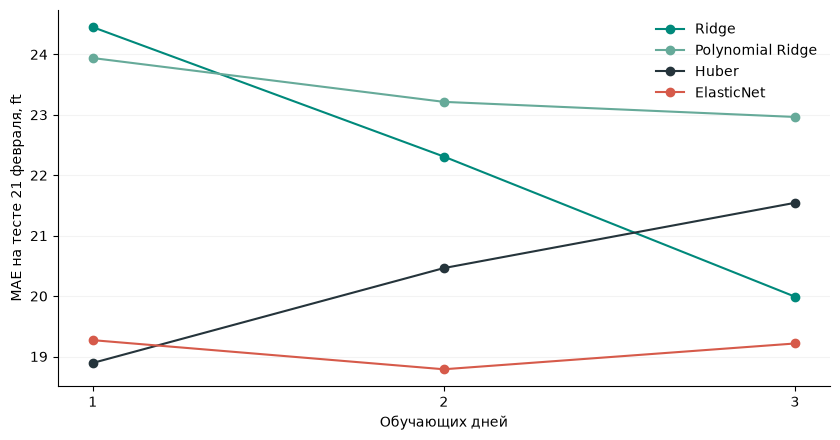

                 model  macro_mae_ft
            ElasticNet     19.215506
                 Ridge     19.990817
                 Huber     21.543410
      Polynomial Ridge     22.964699
Constant vertical rate     56.427594
train_days                1          2          3
model                                            
ElasticNet        19.270755  18.788959  19.215506
Huber             18.893230  20.463406  21.543410
Polynomial Ridge  23.939784  23.214504  22.964699
Ridge             24.451526  22.309494  19.990817


In [3]:
learning = []
for count in [1, 2, 3]:
    subset = train.loc[train.day.isin(dates[:count])]
    for name in FAMILIES:
        model, converged = fit(name, selected[name], subset, features)
        assert converged
        result = summarize(test, forecast(model, test, features), name)
        learning.append({**result, 'train_days': count, 'train_approaches': subset.event_id.nunique()})
learning = pd.DataFrame(learning)
learning.to_csv(base / 'reports/winter_pilot_learning.csv', index=False)
table = learning.pivot(index='model', columns='train_days', values='macro_mae_ft')
display(table.style.format('{:.2f}'))
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for name, color in zip(FAMILIES, ['#00897B', '#66AA99', '#25343B', '#D65A4A']):
    group = learning.loc[learning.model.eq(name)]
    ax.plot(group.train_days, group.macro_mae_ft, marker='o', color=color, label=name)
ax.set(xlabel='Обучающих дней', ylabel='MAE на тесте 21 февраля, ft', xticks=[1, 2, 3])
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.15)
fig.tight_layout()
fig.savefig(base / 'figures/02_winter_pilot.png', dpi=180, bbox_inches='tight')
plt.show()
print(metrics[['model', 'macro_mae_ft']].to_string(index=False))
print(table.to_string())
